In [ ]:
import sys
from pathlib import Path

# Pointer sur root de project
# ROOT = Path.cwd().parent
# sys.path.append(str(ROOT))

import numpy as np
import pandas as pd
import kagglehub
import cv2
import math
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sn
from collections import Counter, defaultdict
from hashlib import sha256
from sklearn.model_selection import train_test_split
import shutil
import yaml

from ultralytics.data.utils import check_det_dataset
from ultralytics import YOLO

# Download latest version
DATASET_PATH = Path(kagglehub.dataset_download("ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes"))
print("Path to dataset files:", DATASET_PATH)

# Dossiers et classes
CLASS_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary",
}

EXTENSIONS = [".jpg", ".jpeg", ".png", ".bmp"]
RANDOM_KEY = 26
SIZE_IMAGE=640
BATCH_SIZE = 16
EPOCHS = 50
PATIENCE = 10


Path to dataset files: /kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes


#### Découverte du dataset

In [ ]:
# Récupérer les images et labels
def get_image_and_label_files(class_path):
    images_path = class_path / "images"
    labels_path = class_path / "labels"

    if not images_path.is_dir() or not labels_path.is_dir():
        return [], []

    image_files = [
        p for p in images_path.iterdir()
        if p.is_file() and p.suffix.lower() in EXTENSIONS
    ]

    label_files = list(labels_path.glob("*.txt"))

    return image_files, label_files


# Vérifier les annotations YOLO
def validate_yolo_annotation(line):
    values = line.split()

    if len(values) != 5:
        raise ValueError("Il faut exactement 5 valeurs")

    class_id = int(values[0])

    if str(class_id) != values[0]:
        raise ValueError("class_id doit être un entier")

    xc, yc, w, h = map(float, values[1:])

    if not all(map(math.isfinite, (xc, yc, w, h))):
        raise ValueError("Valeur NaN ou infinie")

    if not 0 <= class_id < len(CLASS_NAMES):
        raise ValueError(f"class_id invalide : {class_id}")

    if not (0 <= xc <= 1 and 0 <= yc <= 1):
        raise ValueError("Centre hors de l'image")

    if not (0 < w <= 1 and 0 < h <= 1):
        raise ValueError("Width ou height invalide")

    if (
        xc - w / 2 < -1e-6
        or yc - h / 2 < -1e-6
        or xc + w / 2 > 1 + 1e-6
        or yc + h / 2 > 1 + 1e-6
    ):
        raise ValueError("Bounding Box dépasse l'image")


# Valider un fichier label
def validate_label_file(label_path):
    errors = []
    annotations = []

    lines = label_path.read_text(encoding="utf-8").splitlines()

    for line_number, line in enumerate(lines, start=1):
        if not line.strip():
            continue

        try:
            validate_yolo_annotation(line)
            annotations.append(line)

        except (ValueError, OverflowError) as error:
            errors.append(
                f"{label_path} | ligne {line_number} | {error}"
            )

    return annotations, errors, not annotations


# Vérifier la correspondance entre images et labels
def validate_class_dataset(class_path, report):
    classe = class_path.name

    image_files, label_files = get_image_and_label_files(class_path)

    images_by_stem = {p.stem: p for p in image_files}
    labels_by_stem = {p.stem: p for p in label_files}

    report["total_images"] += len(image_files)
    report["total_labels"] += len(label_files)

    report["missing_labels"].extend(
        str(images_by_stem[stem])
        for stem in images_by_stem.keys() - labels_by_stem.keys()
    )

    report["missing_images"].extend(
        str(labels_by_stem[stem])
        for stem in labels_by_stem.keys() - images_by_stem.keys()
    )

    samples = []

    for stem in images_by_stem.keys() & labels_by_stem.keys():
        image_path = images_by_stem[stem]
        label_path = labels_by_stem[stem]

        annotations, errors, is_empty = validate_label_file(label_path)

        report["invalid_annotations"].extend(errors)

        if is_empty:
            report["empty_labels"].append(str(label_path))
            continue

        if errors:
            continue

        samples.append({
            "image_path": image_path,
            "label_path": label_path,
            "class": classe,
            "annotations": annotations,
        })

    return samples


# Affichr le rapport
def print_dataset_report(report):
    print("\n" + "=" * 45)
    print(" RAPPORT D'INTÉGRITÉ DU DATASET")
    print("=" * 45)

    print(f"Total images          : {report['total_images']}")
    print(f"Total fichiers labels : {report['total_labels']}")
    print(f"Images sans label     : {len(report['missing_labels'])}")
    print(f"Labels sans image     : {len(report['missing_images'])}")
    print(f"Labels vides          : {len(report['empty_labels'])}")
    print(f"Annotations invalides : {len(report['invalid_annotations'])}")

    sections = [
        ("Images sans label", report["missing_labels"]),
        ("Labels sans image", report["missing_images"]),
        ("Labels vides", report["empty_labels"]),
        ("Annotations invalides", report["invalid_annotations"]),
    ]

    for title, errors in sections:
        if errors:
            print(f"\n--- {title} (10 premiers) ---")
            for error in errors[:10]:
                print(error)

    print("\nNettoyage effectué en mémoire uniquement.")


# La fonction principale
def load_and_validate_yolo_dataset(dataset_path):
    dataset = []

    report = {
        "total_images": 0,
        "total_labels": 0,
        "missing_labels": [],
        "missing_images": [],
        "empty_labels": [],
        "invalid_annotations": [],
    }

    for split_path in sorted(dataset_path.iterdir()):
        if not split_path.is_dir():
            continue

        for class_path in sorted(split_path.iterdir()):
            if not class_path.is_dir():
                continue

            samples = validate_class_dataset(class_path, report)

            dataset.append({
                "split": split_path.name,
                "class": class_path.name,
                "samples": samples,
            })

    print_dataset_report(report)

    return dataset


dataset = load_and_validate_yolo_dataset(DATASET_PATH)


 RAPPORT D'INTÉGRITÉ DU DATASET
Total images          : 5249
Total fichiers labels : 5249
Images sans label     : 2
Labels sans image     : 2
Labels vides          : 1
Annotations invalides : 0

--- Images sans label (10 premiers) ---
/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/No Tumor/images/image(55).jpg
/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/No Tumor/images/image(61).jpg

--- Labels sans image (10 premiers) ---
/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/No Tumor/labels/image(53).txt
/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/No Tumor/labels/image(60).txt

--- Labels vides (10 premiers) ---
/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/Glioma/labels/gg (342).txt

Nettoyage effectué en mémoire uniquement.
[{'split': 'Train', 'class': 'Glioma', 'samples': [{'image_path': PosixPath('/kaggle/input/datase

In [33]:
for group in dataset:
    print(f"Split : {group['split']}")
    print(f"Classe : {group['class']}")
    print(f"Samples valides : {len(group['samples'])}")
    print("-" * 30)

Split : Train
Classe : Glioma
Samples valides : 1153
------------------------------
Split : Train
Classe : Meningioma
Samples valides : 1449
------------------------------
Split : Train
Classe : No Tumor
Samples valides : 711
------------------------------
Split : Train
Classe : Pituitary
Samples valides : 1424
------------------------------
Split : Val
Classe : Glioma
Samples valides : 135
------------------------------
Split : Val
Classe : Meningioma
Samples valides : 140
------------------------------
Split : Val
Classe : No Tumor
Samples valides : 98
------------------------------
Split : Val
Classe : Pituitary
Samples valides : 136
------------------------------


### Visualisation

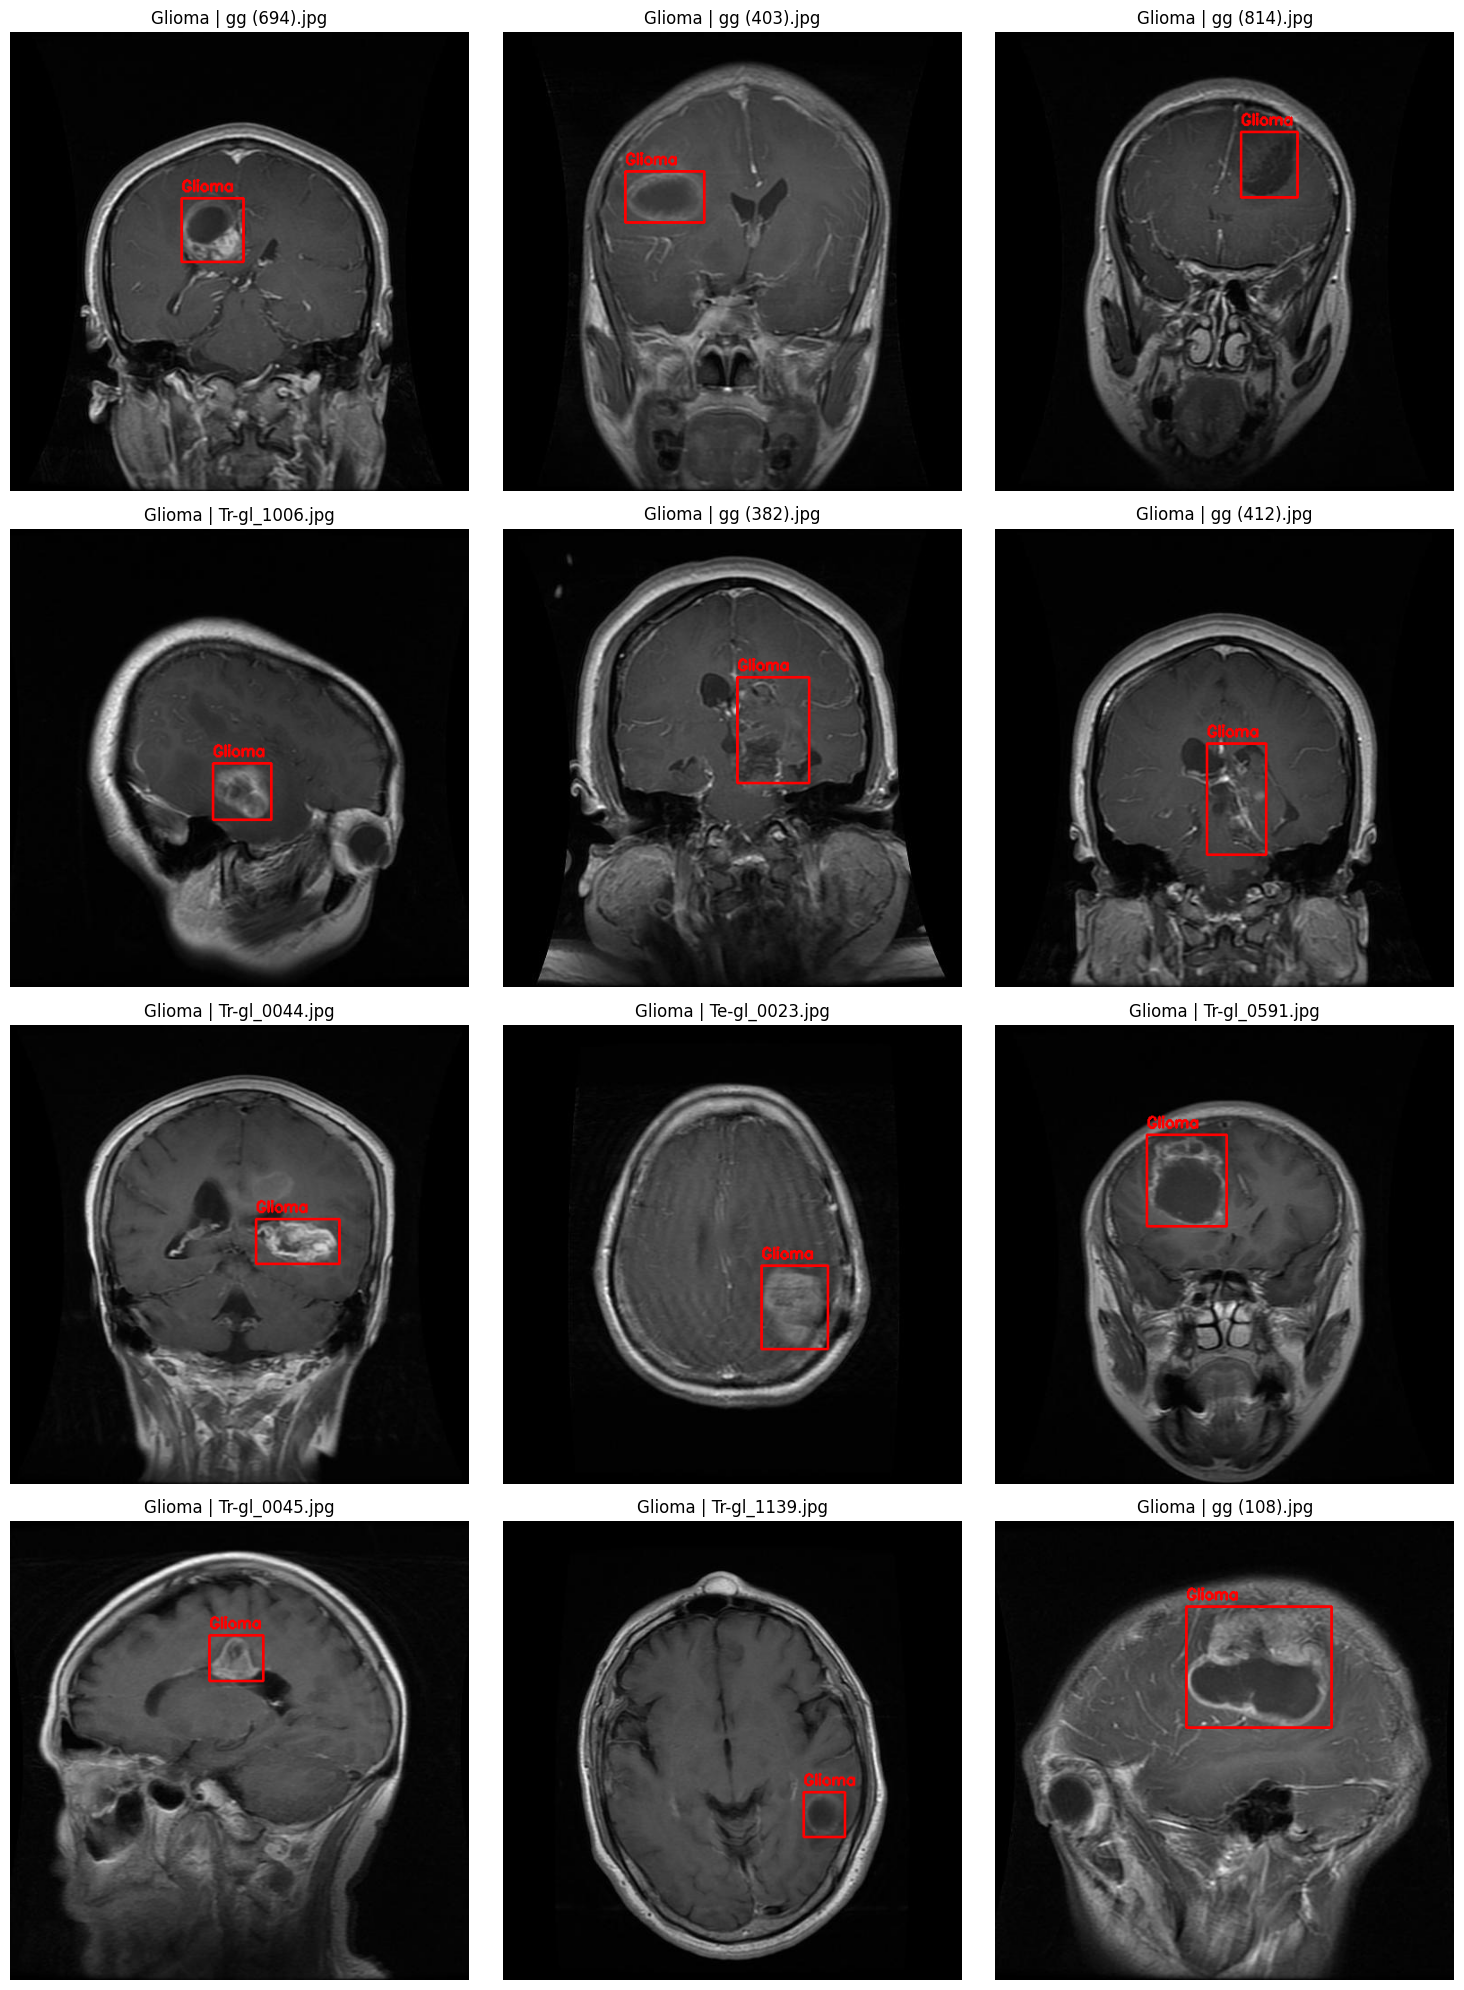

In [27]:
def draw_yolo_bounding_box(dataset, n_images=12):
    selected_samples = [
        sample
        for group in dataset
        for sample in group["samples"]
    ][:n_images]

    if not selected_samples:
        print("Aucun sample valide à afficher.")
        return

    n_cols = 3
    n_rows = math.ceil(len(selected_samples) / n_cols)

    _, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(15, 5 * n_rows),
        squeeze=False
    )
    axes = axes.flatten()

    for ax, sample in zip(axes, selected_samples):
        image_path = sample["image_path"]
        label_path = sample["label_path"]
        classe = sample["class"]

        image = cv2.imread(str(image_path))

        if image is None:
            ax.set_title(f"Image illisible : {image_path.name}")
            ax.axis("off")
            continue

        # OpenCV BGR -> RGB
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        height, width = image.shape[:2]

        # Dessiner les Bounding Boxes
        for line in sample["annotations"]:
            values = line.split()

            if len(values) != 5:
                continue

            class_id = int(values[0])
            xc, yc, w, h = map(float, values[1:])

            # Coordonnées normalisées -> pixels
            x1 = int((xc - w / 2) * width)
            y1 = int((yc - h / 2) * height)
            x2 = int((xc + w / 2) * width)
            y2 = int((yc + h / 2) * height)

            # Garder les coordonnées dans l'image
            x1 = max(0, min(x1, width - 1))
            y1 = max(0, min(y1, height - 1))
            x2 = max(0, min(x2, width - 1))
            y2 = max(0, min(y2, height - 1))

            class_name = (
                CLASS_NAMES[class_id]
                if isinstance(CLASS_NAMES, list)
                else CLASS_NAMES.get(class_id, f"Unknown {class_id}")
            )

            cv2.rectangle(
                image, (x1, y1), (x2, y2), (255, 0, 0), 2
            )

            cv2.putText(
                image,
                class_name,
                (x1, max(y1 - 8, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (255, 0, 0),
                2
            )

        ax.imshow(image)
        ax.set_title(f"{classe} | {image_path.name}")
        ax.axis("off")

    # Masquer les cases non utilisées
    for ax in axes[len(selected_samples):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()


draw_yolo_bounding_box(dataset, n_images=12)

#### Analyse de la distribution des classes

Classe              Images     Pourcentage
------------------------------------------
Meningioma            1589          30.29%
Pituitary             1560          29.74%
Glioma                1288          24.55%
No Tumor               809          15.42%
------------------------------------------
Total                 5246         100.00%


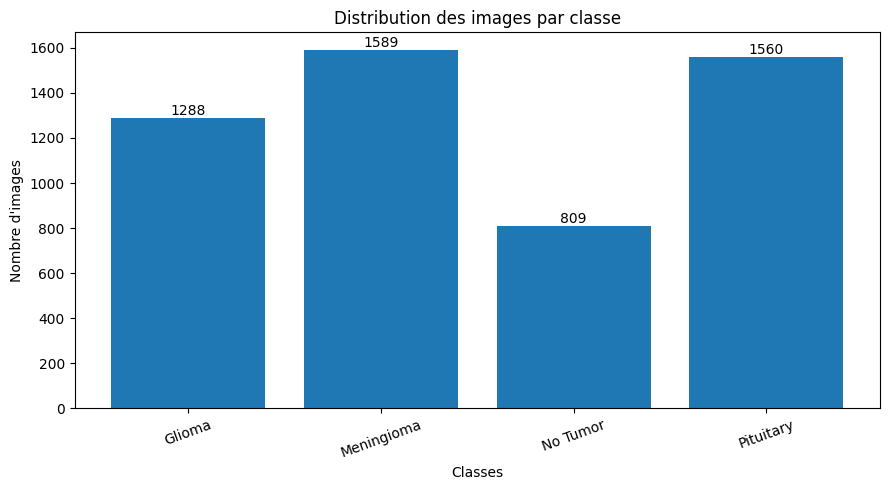

In [29]:
def analyze_class_distribution(dataset):
    class_counts = Counter()

    # Compter les images valides de chaque classe
    for group in dataset:
        for sample in group["samples"]:
            class_counts[sample["class"]] += 1

    total_images = sum(class_counts.values())

    if total_images == 0:
        print("Aucune image valide dans le dataset.")
        return

    # Afficher les résultats
    print(f"{'Classe':<15} {'Images':>10} {'Pourcentage':>15}")
    print("-" * 42)

    for class_name, count in class_counts.most_common():
        percentage = count / total_images * 100

        print(
            f"{class_name:<15} "
            f"{count:>10} "
            f"{percentage:>14.2f}%"
        )

    print("-" * 42)
    print(f"{'Total':<15} {total_images:>10} {'100.00%':>15}")

    # Visualisation
    classes = list(class_counts.keys())
    counts = list(class_counts.values())

    plt.figure(figsize=(9, 5))
    bars = plt.bar(classes, counts)

    plt.title("Distribution des images par classe")
    plt.xlabel("Classes")
    plt.ylabel("Nombre d'images")
    plt.xticks(rotation=20)

    for bar in bars:
        height = bar.get_height()

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            str(int(height)),
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()


analyze_class_distribution(dataset)

#### Vérification des dimensions et de la qualité des images

In [30]:
def analyze_image_quality(dataset):
    dimensions = Counter()
    extensions = Counter()
    unreadable_images = []

    total_images = 0

    for group in dataset:
        for sample in group["samples"]:
            image_path = sample["image_path"]
            total_images += 1

            # Compter les extensions
            extensions[image_path.suffix.lower()] += 1

            # Lire l'image
            image = cv2.imread(str(image_path))

            if image is None:
                unreadable_images.append(str(image_path))
                continue

            # Récupérer les dimensions
            height, width = image.shape[:2]
            dimensions[(width, height)] += 1

    print("=" * 45)
    print("ANALYSE DE LA QUALITÉ DES IMAGES")
    print("=" * 45)

    print(f"Total images       : {total_images}")
    print(f"Images illisibles  : {len(unreadable_images)}")
    print(f"Dimensions uniques : {len(dimensions)}")

    print("\nFormats des images :")
    for extension, count in extensions.most_common():
        print(f"{extension}: {count}")

    print("\nDimensions les plus fréquentes :")
    for (width, height), count in dimensions.most_common(10):
        print(f"{width}x{height}: {count} images")

    if unreadable_images:
        print("\nExemples d'images illisibles :")
        for path in unreadable_images[:10]:
            print(path)

    return {
        "total_images": total_images,
        "dimensions": dimensions,
        "extensions": extensions,
        "unreadable_images": unreadable_images,
    }


image_report = analyze_image_quality(dataset)

KeyboardInterrupt: 

#### Vérifier les doublons d’images

In [31]:
def find_duplicate_images(dataset):
    image_hashes = defaultdict(list)

    for group in dataset:
        for sample in group["samples"]:
            image_path = sample["image_path"]

            try:
                with image_path.open("rb") as file:
                    file_hash = sha256(file.read()).hexdigest()

                image_hashes[file_hash].append(str(image_path))

            except OSError as error:
                print(f"Erreur de lecture : {image_path}")
                print(error)

    duplicates = {
        file_hash: paths
        for file_hash, paths in image_hashes.items()
        if len(paths) > 1
    }

    print("=" * 45)
    print("RAPPORT DES DOUBLONS")
    print("=" * 45)
    print(f"Groupes d'images identiques : {len(duplicates)}")

    for paths in list(duplicates.values())[:10]:
        print("\nImages identiques :")
        for path in paths:
            print(f" - {path}")

    return duplicates


duplicates = find_duplicate_images(dataset)

KeyboardInterrupt: 

#### Data spliting

In [ ]:
dataset = [
    sample
    for group in dataset
    for sample in group["samples"]
]

print(f"Total samples : {len(dataset)}")


# 70% Train et 30% temporaire
train, temp = train_test_split(
    dataset,
    test_size=0.30,
    random_state=RANDOM_KEY,
    stratify=[sample["class"] for sample in dataset]
)

# Diviser les 30% restants en Val (15%) et Test (15%)
val, test = train_test_split(
    temp,
    test_size=0.50,
    random_state=42,
    stratify=[sample["class"] for sample in temp]
)

print(f"Train : {len(train)} samples ({len(train) / len(dataset) * 100:.2f}%)")
print(f"Val   : {len(val)} samples ({len(val) / len(dataset) * 100:.2f}%)")
print(f"Test  : {len(test)} samples ({len(test) / len(dataset) * 100:.2f}%)")
print(f"Total : {len(train) + len(val) + len(test)} samples")


# Vérifier la distribution des classes
def analyze_split_distribution(train, val, test):
    splits = {
        "Train": train,
        "Validation": val,
        "Test": test,
    }

    for split_name, samples in splits.items():
        counts = Counter(sample["class"] for sample in samples)
        total = len(samples)

        print(f"\n--- {split_name} ({total} samples) ---")

        for classe, count in sorted(counts.items()):
            percentage = count / total * 100
            print(f"{classe:<15} : {count:>4} ({percentage:.2f}%)")

analyze_split_distribution(train, val, test)

Train : 3672 samples (70.00%)
Val   : 787 samples (15.00%)
Test  : 787 samples (15.00%)
Total : 5246 samples

--- Train (3672 samples) ---
Glioma          :  902 (24.56%)
Meningioma      : 1112 (30.28%)
No Tumor        :  566 (15.41%)
Pituitary       : 1092 (29.74%)

--- Validation (787 samples) ---
Glioma          :  193 (24.52%)
Meningioma      :  238 (30.24%)
No Tumor        :  122 (15.50%)
Pituitary       :  234 (29.73%)

--- Test (787 samples) ---
Glioma          :  193 (24.52%)
Meningioma      :  239 (30.37%)
No Tumor        :  121 (15.37%)
Pituitary       :  234 (29.73%)


##### Préparer la structure du dataset pour YOLOv8

In [ ]:
YOLO_DATASET_PATH = Path("../dataset_yolo")

SPLITS = {
    "train": train,
    "val": val,
    "test": test,
}

def prepare_yolo_dataset(splits, output_path):
    output_path = Path(output_path)

    for split_name, samples in splits.items():
        images_dir = output_path / "images" / split_name
        labels_dir = output_path / "labels" / split_name

        images_dir.mkdir(parents=True, exist_ok=True)
        labels_dir.mkdir(parents=True, exist_ok=True)

        for sample in samples:
            image_path = Path(sample["image_path"])
            label_path = Path(sample["label_path"])

            # Nom unique pour éviter les collisions
            unique_name = f"{sample['class']}_{image_path.stem}"

            # Conserver l'extension originale
            new_image_path = images_dir / f"{unique_name}{image_path.suffix.lower()}"
            new_label_path = labels_dir / f"{unique_name}.txt"

            shutil.copy2(image_path, new_image_path)
            shutil.copy2(label_path, new_label_path)

        print(
            f"{split_name}: {len(samples)} samples copiés "
            f"vers {images_dir}"
        )


prepare_yolo_dataset(SPLITS, YOLO_DATASET_PATH)

KeyboardInterrupt: 

#### Vérifier l’intégrité du dataset YOLO

In [ ]:
def verify_yolo_dataset(dataset_path):
    dataset_path = Path(dataset_path)

    for split in ("train", "val", "test"):
        images_dir = dataset_path / "images" / split
        labels_dir = dataset_path / "labels" / split

        image_files = [
            p for p in images_dir.iterdir()
            if p.is_file() and p.suffix.lower() in EXTENSIONS
        ]

        label_files = list(labels_dir.glob("*.txt"))

        # Comparer les noms sans extension
        image_stems = {p.stem for p in image_files}
        label_stems = {p.stem for p in label_files}

        missing_labels = image_stems - label_stems
        missing_images = label_stems - image_stems

        print(f"\n--- {split.upper()} ---")
        print(f"Images : {len(image_files)}")
        print(f"Labels : {len(label_files)}")
        print(f"Images sans label : {len(missing_labels)}")
        print(f"Labels sans image : {len(missing_images)}")

        if missing_labels:
            print("Exemples d'images sans label :", list(missing_labels)[:5])

        if missing_images:
            print("Exemples de labels sans image :", list(missing_images)[:5])

        if not missing_labels and not missing_images:
            print("Intégrité des paires : OK")

verify_yolo_dataset(YOLO_DATASET_PATH)

#### Créer le fichier data.yaml

In [ ]:
data_yaml = {
    "path": str(YOLO_DATASET_PATH.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": CLASS_NAMES,
    "nc": 4, # nomber des classes
}

yaml_path = YOLO_DATASET_PATH / "data.yaml"

with open(yaml_path, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        data_yaml,
        file,
        sort_keys=False,
        allow_unicode=True,
    )

print(f"Fichier créé : {yaml_path.resolve()}")

#### Charger et vérifier le dataset avec Ultralytics

In [ ]:
YOLO_DATASET_PATH = Path("dataset_yolo")
yaml_path = YOLO_DATASET_PATH / "data.yaml"

# 1. Vérifier que le fichier YAML existe
if not yaml_path.exists():
    raise FileNotFoundError(f"Fichier introuvable : {yaml_path}")

# 2. Vérifier les dossiers images et labels
for split in ["train", "val", "test"]:
    images_dir = YOLO_DATASET_PATH / "images" / split
    labels_dir = YOLO_DATASET_PATH / "labels" / split

    if not images_dir.is_dir():
        raise FileNotFoundError(f"Dossier introuvable : {images_dir}")

    if not labels_dir.is_dir():
        raise FileNotFoundError(f"Dossier introuvable : {labels_dir}")

    image_count = sum(
        1 for p in images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp"
        }
    )

    label_count = sum(
        1 for p in labels_dir.glob("*.txt")
        if p.is_file()
    )

    print(f"{split.upper()} :")
    print(f"  Images : {image_count}")
    print(f"  Labels : {label_count}")

# 3. Vérifier la configuration avec Ultralytics
data = check_det_dataset(str(yaml_path))

print("\nDataset YAML validé par Ultralytics.")
print("Classes :", data["names"])
print("Nombre de classes :", data["nc"])

#### Analyser la distribution des classes dans les Bounding Boxes

In [ ]:
def analyze_yolo_annotations(dataset_path):
    dataset_path = Path(dataset_path)

    for split in ("train", "val", "test"):
        labels_dir = dataset_path / "labels" / split

        box_counts = Counter()
        images_per_class = Counter()
        invalid_class_ids = []

        for label_path in labels_dir.glob("*.txt"):
            seen_classes = set()

            for line_number, line in enumerate(
                label_path.read_text(encoding="utf-8").splitlines(),
                start=1,
            ):
                if not line.strip():
                    continue

                values = line.split()

                if len(values) != 5:
                    continue

                try:
                    class_id = int(values[0])
                except ValueError:
                    continue

                if class_id not in CLASS_NAMES:
                    invalid_class_ids.append(
                        f"{label_path.name}, ligne {line_number}: {class_id}"
                    )
                    continue

                box_counts[class_id] += 1
                seen_classes.add(class_id)

            images_per_class.update(seen_classes)

        print(f"\n--- {split.upper()} ---")

        for class_id, name in CLASS_NAMES.items():
            print(
                f"{name:<12} | "
                f"Bounding Boxes: {box_counts[class_id]:5} | "
                f"Images avec cette classe: {images_per_class[class_id]:5}"
            )

        print("Class IDs invalides :", len(invalid_class_ids))

        if invalid_class_ids:
            print("Exemples :", invalid_class_ids[:5])


analyze_yolo_annotations(YOLO_DATASET_PATH)

##### Visualiser les Data Augmentations.

In [ ]:
# 1. Lire les annotations YOLO
def parse_annotations(annotations):
    boxes = []

    for line in annotations:
        class_id, xc, yc, w, h = line.split()

        boxes.append((
            int(class_id),
            float(xc),
            float(yc),
            float(w),
            float(h)
        ))

    return boxes


# 2. Dessiner les Bounding Boxes
def draw_boxes(image, boxes):
    result = image.copy()

    height, width = result.shape[:2]

    for class_id, xc, yc, w, h in boxes:

        # Convertir les coordonnées YOLO en pixels
        x1 = int((xc - w / 2) * width)
        y1 = int((yc - h / 2) * height)
        x2 = int((xc + w / 2) * width)
        y2 = int((yc + h / 2) * height)

        # Dessiner la Bounding Box
        cv2.rectangle(
            result,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

        # Nom de la classe
        label = CLASS_NAMES[class_id]

        cv2.putText(
            result,
            label,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    return result


# 3. Appliquer Horizontal Flip sur l'image et les boxes
def horizontal_flip(image, boxes):

    # Retourner l'image horizontalement
    flipped_image = cv2.flip(image, 1)

    flipped_boxes = []

    for class_id, xc, yc, w, h in boxes:

        # Mettre à jour le centre horizontal
        new_xc = 1 - xc

        flipped_boxes.append((
            class_id,
            new_xc,
            yc,
            w,
            h
        ))

    return flipped_image, flipped_boxes


# 4. Choisir un sample du dataset train
sample = train[0]

# Lire l'image
image_path = Path(sample["image_path"])
image_bgr = cv2.imread(str(image_path))

if image_bgr is None:
    raise ValueError(f"Impossible de lire l'image : {image_path}")

# Convertir BGR vers RGB
image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Lire les annotations déjà chargées en mémoire
boxes = parse_annotations(sample["annotations"])

if not boxes:
    raise ValueError("Cette image ne contient aucune Bounding Box.")


# 5. Image originale avec Bounding Boxes
original_display = draw_boxes(image, boxes)


# 6. Image augmentée avec Bounding Boxes mises à jour
flipped_image, flipped_boxes = horizontal_flip(image, boxes)

flipped_display = draw_boxes(flipped_image, flipped_boxes)


# 7. Afficher les deux images côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(original_display)
axes[0].set_title("Image originale")
axes[0].axis("off")

axes[1].imshow(flipped_display)
axes[1].set_title("Image après Horizontal Flip")
axes[1].axis("off")

plt.tight_layout()
plt.show()  

#### Préparer le premier entraînement

In [ ]:
# Charger YOLOv8 Nano pré-entraîné
model = YOLO("yolov8n.pt") # pretrained weights of yolov8n.pt

# Lancer l'entraînement
results = model.train(
    data=str(YOLO_DATASET_PATH / "data.yaml"),
    epochs=EPOCHS,
    imgsz=SIZE_IMAGE,
    batch=BATCH_SIZE,
    seed=RANDOM_KEY,
    patience=PATIENCE,

    # Data Augmentation
    fliplr=0.5,
    flipud=0.0,
    degrees=5.0,
    translate=0.05,
    scale=0.10,
    mosaic=0.0,
    mixup=0.0,

    project="../runs/neurovision",
    name="yolov8n_baseline",
)

#### Analyser results.csv

In [ ]:
# 1. Chemin vers les résultats d'entraînement
results_path = Path(
    "../runs/neurovision/yolov8n_baseline/results.csv"
)

if not results_path.exists():
    raise FileNotFoundError(
        f"Fichier results.csv introuvable : {results_path}\n"
        "Vérifie que l'entraînement est terminé et le chemin."
    )

# 2. Lire le fichier CSV
df = pd.read_csv(results_path)

# Nettoyer les espaces dans les noms des colonnes
df.columns = df.columns.str.strip()

print("Colonnes disponibles :")
print(df.columns.tolist())

print("\nDernières lignes :")
print(df.tail())

# 3. Afficher les courbes de Loss
loss_columns = [
    col for col in [
        "train/box_loss",
        "train/cls_loss",
        "train/dfl_loss",
        "val/box_loss",
        "val/cls_loss",
        "val/dfl_loss"
    ]
    if col in df.columns
]

if loss_columns:
    df.plot(
        x="epoch",
        y=loss_columns,
        figsize=(12, 6),
        title="YOLOv8 - Évolution des Loss"
    )
    plt.ylabel("Loss")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune colonne Loss reconnue.")

# 4. Afficher les métriques de validation
metric_columns = [
    col for col in [
        "metrics/precision(B)",
        "metrics/recall(B)",
        "metrics/mAP50(B)",
        "metrics/mAP50-95(B)"
    ]
    if col in df.columns
]

if metric_columns:
    df.plot(
        x="epoch",
        y=metric_columns,
        figsize=(12, 6),
        title="YOLOv8 - Métriques de validation"
    )
    plt.ylabel("Score")
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("Aucune colonne de métriques reconnue.")

# 5. Identifier l'epoch avec le meilleur mAP50-95
map_column = "metrics/mAP50-95(B)"

if map_column in df.columns:
    best_index = df[map_column].idxmax()
    best_row = df.loc[best_index]

    print("\nMeilleur résultat mAP50-95 :")
    print("Epoch :", int(best_row["epoch"]) + 1)
    print("mAP50-95 :", round(best_row[map_column], 4))

    if "metrics/mAP50(B)" in df.columns:
        print(
            "mAP50 :",
            round(best_row["metrics/mAP50(B)"], 4)
        )

    if "metrics/precision(B)" in df.columns:
        print(
            "Precision :",
            round(best_row["metrics/precision(B)"], 4)
        )

    if "metrics/recall(B)" in df.columns:
        print(
            "Recall :",
            round(best_row["metrics/recall(B)"], 4)
        )


#### Évaluer le modèle sur le jeu de test

In [ ]:
# 1. Chemins
YOLO_DATASET_PATH = Path("../dataset_yolo")
MODEL_PATH = Path(
    "../runs/neurovision/yolov8n_baseline/weights/best.pt"
)

DATA_YAML = YOLO_DATASET_PATH / "data.yaml"

# 2. Vérifier les fichiers
if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"Modèle introuvable : {MODEL_PATH}"
    )

if not DATA_YAML.exists():
    raise FileNotFoundError(
        f"Fichier YAML introuvable : {DATA_YAML}"
    )

# 3. Charger le meilleur modèle
model = YOLO(str(MODEL_PATH))

# 4. Évaluer sur le jeu de test
metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=16,
    plots=True,
    project="../runs/neurovision",
    name="test_evaluation"
)

# 5. Afficher les métriques globales
print("\n===== TEST METRICS =====")

print(f"Precision    : {metrics.box.mp:.4f}")
print(f"Recall       : {metrics.box.mr:.4f}")
print(f"mAP50        : {metrics.box.map50:.4f}")
print(f"mAP50-95     : {metrics.box.map:.4f}")

# 6. Afficher les résultats par classe
print("\n===== METRICS PAR CLASSE =====")

for class_id, class_name in model.names.items():
    print(f"\nClasse : {class_name}")
    print(f"mAP50-95 : {metrics.box.maps[class_id]:.4f}")


#### Visualiser les prédictions sur des IRM de test

In [ ]:
# 1. Charger le modèle entraîné
MODEL_PATH = Path(
    "../runs/neurovision/yolov8n_baseline/weights/best.pt"
)

TEST_IMAGES_DIR = Path("../dataset_yolo/images/test")

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Modèle introuvable : {MODEL_PATH}")

if not TEST_IMAGES_DIR.exists():
    raise FileNotFoundError(
        f"Dossier test introuvable : {TEST_IMAGES_DIR}"
    )

model = YOLO(str(MODEL_PATH))

# 2. Sélectionner 6 images

image_paths = sorted(
    path for path in TEST_IMAGES_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in EXTENSIONS
)[:6]

if not image_paths:
    raise ValueError("Aucune image trouvée dans le dossier test.")

# 3. Faire les prédictions
results = model.predict(
    source=[str(path) for path in image_paths],
    imgsz=640,
    conf=0.25,
    save=True,
    project="../runs/neurovision",
    name="test_predictions",
    exist_ok=True
)

# 4. Afficher les images avec les prédictions
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, result in zip(axes, results):
    # plot() retourne une image en BGR
    annotated_image = result.plot()

    # Convertir BGR vers RGB pour Matplotlib
    annotated_image = cv2.cvtColor(
        annotated_image, cv2.COLOR_BGR2RGB
    )

    ax.imshow(annotated_image)
    ax.set_title(Path(result.path).name)
    ax.axis("off")

# Masquer les cases inutilisées si moins de 6 images
for ax in axes[len(results):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"{len(results)} images affichées.")
print("Résultats sauvegardés dans :")
print("runs/neurovision/test_predictions/")
